# Predicting Sales from Influencer Campaign Data

**Role:** Data scientist supporting a marketing / growth team.

**Goal:** Estimate product units sold from messy influencer-campaign attributes, explain which levers matter, and ship **one function** that future messy campaign files can be scored with:

```python
preds = predict_campaign_sales(messy_df)
```

Train: `data/messy_train_data.csv` (8,000 campaigns, with sales).  
Test: `data/messy_test_data.csv` (2,000 campaigns, **no** sales labels).

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["figure.dpi"] = 100

DATA_DIR = Path("data")
train_raw = pd.read_csv(DATA_DIR / "messy_train_data.csv")
test_raw = pd.read_csv(DATA_DIR / "messy_test_data.csv")

print("Train:", train_raw.shape, "Test:", test_raw.shape)
print("Train columns:", list(train_raw.columns))
print("Test columns:", list(test_raw.columns))
train_raw.head()

Train: (8000, 8) Test: (2000, 7)
Train columns: ['Followers', 'EngagementRate (%)', 'AdSpend (GBP)', 'ContentQuality', 'Sales (Units)', 'ID', 'Timestamp', 'Notes']
Test columns: ['Followers', 'EngagementRate (%)', 'AdSpend (GBP)', 'ContentQuality', 'ID', 'Timestamp', 'Notes']


,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,Sales (Units),ID,Timestamp,Notes
0,106572.0,2.573174871146172,2614.3781948587675,5.275680,6340,9254,2021-11-27,Pending
1,77583.0,0.9394984315675532,4975.962514379572,8.756268,5793,1561,2022-02-13,Review
2,92832.0,2.1761012652155296,4107.769534318886,6.454727,8104,1670,2023-09-25,Pending
3,53565.0,1.4783757541486553,4293.330464613049,4.312813,7293,6087,2023-02-15,Review
4,121079.0,3.3741976179329356,5343.549440897207,3.769047,14396,6669,2023-05-28,NaN


## A. Data understanding and cleaning

The files were stitched from different sources. Typical issues:

- Currency strings (`£5480`) and percent strings (`3.2%`) mixed with plain numbers
- About 2% missing values on each numeric campaign field
- Follower counts on mixed scales (values under 1,000 sit next to 40k–150k)
- Impossible outliers (billions of followers, negative spend/engagement)
- Extra fields: `ID`, `Timestamp`, `Notes` (status labels only)

In [2]:
def peek_messiness(df, name):
    print(f"\n=== {name} ===")
    print(df.dtypes)
    print("\nMissing counts:\n", df.isna().sum())
    for col in ["EngagementRate (%)", "AdSpend (GBP)"]:
        s = df[col].astype(str)
        print(f"{col}: £={s.str.contains('£', na=False).sum()}, %={s.str.contains('%', na=False).sum()}")
    f = pd.to_numeric(df["Followers"], errors="coerce")
    print(f"Followers < 1000: {(f < 1000).sum()}, > 1e6: {(f > 1e6).sum()}, missing: {f.isna().sum()}")

peek_messiness(train_raw, "TRAIN")
peek_messiness(test_raw, "TEST")
print("\nNotes (train):")
print(train_raw["Notes"].value_counts(dropna=False))
print("\nTimestamp range:", train_raw["Timestamp"].min(), "→", train_raw["Timestamp"].max())
print("Sales missing:", train_raw["Sales (Units)"].isna().sum())


=== TRAIN ===
Followers             float64
EngagementRate (%)        str
AdSpend (GBP)             str
ContentQuality        float64
Sales (Units)           int64
ID                      int64
Timestamp                 str
Notes                     str
dtype: object

Missing counts:
 Followers              160
EngagementRate (%)     160
AdSpend (GBP)          159
ContentQuality         160
Sales (Units)            0
ID                       0
Timestamp                0
Notes                 2652
dtype: int64
EngagementRate (%): £=0, %=200
AdSpend (GBP): £=200, %=0
Followers < 1000: 200, > 1e6: 5, missing: 160

=== TEST ===
Followers             float64
EngagementRate (%)        str
AdSpend (GBP)             str
ContentQuality        float64
ID                      int64
Timestamp                 str
Notes                     str
dtype: object

Missing counts:
 Followers              40
EngagementRate (%)     40
AdSpend (GBP)          40
ContentQuality         40
ID                   

### Reusable pipeline

Cleaning, features, and the model are one object. After `fit` on messy train, **`predict_campaign_sales(messy_df)`** is the only function a marketing analyst needs.

Rules (learned on train, frozen for the future):

| Issue | Handling |
| --- | --- |
| `£`, `%`, commas, optional `k` suffix | Parse to numbers; engagement stays on a **percent** scale (do not ÷ 100) |
| Followers `< 1000` | Treat as thousands (`× 1000`) |
| Negative spend / engagement | Treat as missing, then impute |
| Billion-scale outliers | Cap at the train 99.5th percentile |
| Missing numerics | Train median |
| Extra columns | Ignored |
| Missing expected columns | Filled with train medians |
| Row count | Never drop rows — one prediction per input row |
| Predictions | Clipped at 0 units |

In [3]:
COL_FOLLOWERS = "Followers"
COL_ENG = "EngagementRate (%)"
COL_SPEND = "AdSpend (GBP)"
COL_QUALITY = "ContentQuality"
COL_SALES = "Sales (Units)"
COL_ID = "ID"
COL_TS = "Timestamp"

FEATURE_ORDER = [
    "Followers",
    "log_followers",
    "EngagementRate",
    "AdSpend",
    "log_adspend",
    "ContentQuality",
    "engaged_audience",
    "spend_per_1k_followers",
    "eng_x_quality",
    "log_followers_x_eng",
    "month",
    "is_weekend",
]


def _parse_numeric(series: pd.Series) -> pd.Series:
    """Turn messy campaign numbers into floats."""
    if series is None:
        return pd.Series(dtype=float)
    if pd.api.types.is_numeric_dtype(series):
        return pd.to_numeric(series, errors="coerce")

    text = series.astype(str).str.strip()
    text = (
        text.str.replace("£", "", regex=False)
        .str.replace("%", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.replace("GBP", "", regex=False)
        .str.strip()
    )
    text = text.replace(
        {"nan": np.nan, "None": np.nan, "N/A": np.nan, "NA": np.nan, "": np.nan, "<NA>": np.nan}
    )

    k_mask = text.str.endswith(("k", "K"), na=False)
    out = pd.Series(np.nan, index=series.index, dtype=float)
    if k_mask.any():
        out.loc[k_mask] = pd.to_numeric(text.loc[k_mask].str[:-1], errors="coerce") * 1000
    out.loc[~k_mask] = pd.to_numeric(text.loc[~k_mask], errors="coerce")
    return out


class CampaignSalesPipeline:
    """Fit on messy train campaigns; predict from messy future campaigns."""

    follower_k_threshold = 1000
    cap_quantile = 0.995

    def __init__(self, model=None):
        self.model = model if model is not None else HistGradientBoostingRegressor(
            random_state=42, max_depth=6, learning_rate=0.08, max_iter=300
        )
        self.medians_ = {}
        self.caps_ = {}
        self.model_ = None
        self.feature_names_ = FEATURE_ORDER.copy()

    def _get_col(self, df, name):
        if name in df.columns:
            return df[name]
        aliases = {
            COL_FOLLOWERS: ["followers", "Follower", "follower_count"],
            COL_ENG: ["EngagementRate", "engagement_rate", "Engagement"],
            COL_SPEND: ["AdSpend", "ad_spend", "Spend"],
            COL_QUALITY: ["content_quality", "Quality"],
            COL_TS: ["timestamp", "Date", "date"],
            COL_SALES: ["Sales", "sales", "Sales_Units"],
        }
        for alt in aliases.get(name, []):
            if alt in df.columns:
                return df[alt]
        return pd.Series(np.nan, index=df.index)

    def _clean(self, df: pd.DataFrame, *, fit: bool) -> pd.DataFrame:
        out = pd.DataFrame(index=df.index)
        if COL_ID in df.columns:
            out[COL_ID] = df[COL_ID]

        followers = _parse_numeric(self._get_col(df, COL_FOLLOWERS))
        engagement = _parse_numeric(self._get_col(df, COL_ENG))
        spend = _parse_numeric(self._get_col(df, COL_SPEND))
        quality = _parse_numeric(self._get_col(df, COL_QUALITY))

        # Mixed follower scale: 20–199 looks like thousands vs typical ~99k.
        small = followers.notna() & (followers > 0) & (followers < self.follower_k_threshold)
        followers = followers.copy()
        followers.loc[small] = followers.loc[small] * 1000

        engagement = engagement.where(engagement >= 0)
        spend = spend.where(spend >= 0)
        quality = quality.where((quality >= 1) & (quality <= 10))

        ts = pd.to_datetime(self._get_col(df, COL_TS), errors="coerce")
        out["month"] = ts.dt.month
        out["is_weekend"] = ts.dt.dayofweek.ge(5).astype(float)
        out.loc[ts.isna(), ["month", "is_weekend"]] = np.nan

        out[COL_FOLLOWERS] = followers
        out["EngagementRate"] = engagement
        out["AdSpend"] = spend
        out[COL_QUALITY] = quality

        if COL_SALES in df.columns:
            out[COL_SALES] = pd.to_numeric(df[COL_SALES], errors="coerce")

        numeric_for_stats = [COL_FOLLOWERS, "EngagementRate", "AdSpend", COL_QUALITY, "month", "is_weekend"]
        if fit:
            self.caps_ = {
                COL_FOLLOWERS: float(out[COL_FOLLOWERS].quantile(self.cap_quantile)),
                "AdSpend": float(out["AdSpend"].quantile(self.cap_quantile)),
            }
            self.medians_ = {c: float(out[c].median()) for c in numeric_for_stats}

        out[COL_FOLLOWERS] = out[COL_FOLLOWERS].clip(upper=self.caps_[COL_FOLLOWERS])
        out["AdSpend"] = out["AdSpend"].clip(upper=self.caps_["AdSpend"])

        for c in numeric_for_stats:
            out[c] = out[c].fillna(self.medians_[c])

        return out

    def _features(self, cleaned: pd.DataFrame) -> pd.DataFrame:
        f = cleaned[COL_FOLLOWERS].clip(lower=0)
        e = cleaned["EngagementRate"].clip(lower=0)
        s = cleaned["AdSpend"].clip(lower=0)
        q = cleaned[COL_QUALITY]
        eng_frac = e / 100.0
        X = pd.DataFrame(
            {
                "Followers": f,
                "log_followers": np.log1p(f),
                "EngagementRate": e,
                "AdSpend": s,
                "log_adspend": np.log1p(s),
                "ContentQuality": q,
                "engaged_audience": f * eng_frac,
                "spend_per_1k_followers": s / (f / 1000.0 + 1e-6),
                "eng_x_quality": e * q,
                "log_followers_x_eng": np.log1p(f) * e,
                "month": cleaned["month"],
                "is_weekend": cleaned["is_weekend"],
            },
            index=cleaned.index,
        )
        return X[self.feature_names_]

    def fit(self, messy_df: pd.DataFrame, y=None):
        cleaned = self._clean(messy_df, fit=True)
        X = self._features(cleaned)
        if y is None:
            if COL_SALES not in cleaned.columns:
                raise ValueError("Train data must include Sales (Units) or pass y explicitly.")
            y = cleaned[COL_SALES]
        y = pd.to_numeric(pd.Series(y, index=cleaned.index), errors="coerce")
        mask = y.notna()
        self.model_ = self.model
        self.model_.fit(X.loc[mask], y.loc[mask])
        self.n_features_ = X.shape[1]
        return self

    def predict(self, messy_df: pd.DataFrame) -> pd.Series:
        if self.model_ is None:
            raise RuntimeError("Call fit() before predict().")
        cleaned = self._clean(messy_df, fit=False)
        X = self._features(cleaned)
        preds = np.clip(self.model_.predict(X), 0, None)
        out = pd.Series(preds, index=messy_df.index, name="Sales_Predicted")
        if len(out) != len(messy_df):
            raise RuntimeError("Pipeline dropped rows; this is a bug.")
        return out

    def transform_features(self, messy_df: pd.DataFrame, *, fit: bool = False) -> pd.DataFrame:
        cleaned = self._clean(messy_df, fit=fit)
        feats = self._features(cleaned)
        if COL_SALES in cleaned.columns:
            feats[COL_SALES] = cleaned[COL_SALES]
        if COL_ID in cleaned.columns:
            feats[COL_ID] = cleaned[COL_ID]
        return feats


# Learner used only to freeze cleaning stats + produce an analysis table.
cleaner = CampaignSalesPipeline()
train_feat = cleaner.transform_features(train_raw, fit=True)
print("Cleaned train features:", train_feat.shape)
print("Caps:", cleaner.caps_)
print("Medians:", {k: round(v, 2) for k, v in cleaner.medians_.items()})
train_feat.describe().T.round(2)

Cleaned train features: (8000, 14)
Caps: {'Followers': 179316.35000000003, 'AdSpend': 8767.68830812039}
Medians: {'Followers': 100000.0, 'EngagementRate': 2.8, 'AdSpend': 5006.49, 'ContentQuality': 5.47, 'month': 6.0, 'is_weekend': 0.0}


,count,mean,std,min,25%,50%,75%,max
Followers,8000.0,100056.19,29589.12,20000.00,80458.50,100000.00,119885.25,179316.35
log_followers,8000.0,11.46,0.34,9.90,11.30,11.51,11.69,12.10
EngagementRate,8000.0,2.78,1.29,0.50,1.68,2.80,3.89,5.00
AdSpend,8000.0,4995.44,1456.01,1000.00,4001.34,5006.49,5982.00,8767.69
log_adspend,8000.0,8.47,0.33,6.91,8.29,8.52,8.70,9.08
ContentQuality,8000.0,5.49,2.58,1.00,3.27,5.47,7.74,10.00
engaged_audience,8000.0,2780.47,1569.33,110.23,1498.44,2617.94,3857.20,8659.68
spend_per_1k_followers,8000.0,56.21,31.31,7.01,37.46,49.66,66.44,415.51
eng_x_quality,8000.0,15.22,10.52,0.55,6.55,12.82,21.73,49.86
log_followers_x_eng,8000.0,31.87,14.83,5.24,19.22,32.11,44.55,60.27


Cleaning is fitted on **train only**. The same medians and caps are applied to test (and any future file).

In [4]:
test_feat = cleaner.transform_features(test_raw, fit=False)
print("Test features:", test_feat.shape)
print("Any remaining NaNs in train features?", train_feat[FEATURE_ORDER].isna().any().any())
print("Any remaining NaNs in test features?", test_feat[FEATURE_ORDER].isna().any().any())

Test features: (2000, 13)
Any remaining NaNs in train features? False
Any remaining NaNs in test features? False


## B. Exploratory analysis

Plots use the cleaned **training** campaigns only.

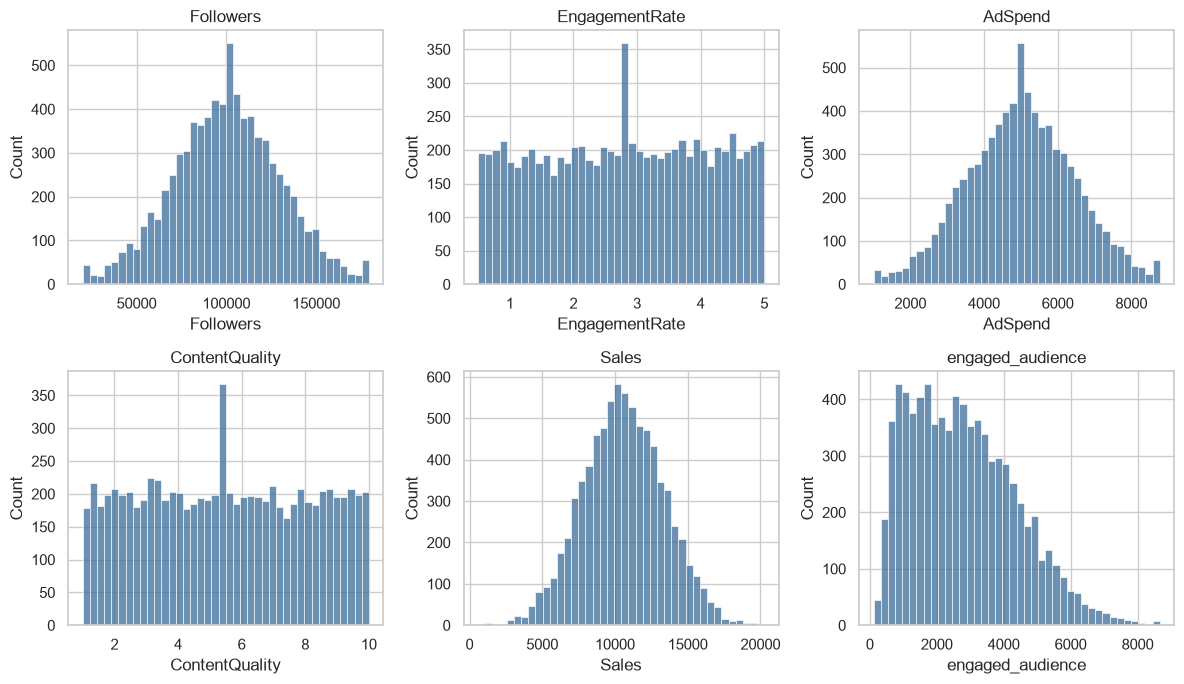

In [5]:
eda = train_feat.copy()
eda["Sales"] = eda[COL_SALES]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
cols = ["Followers", "EngagementRate", "AdSpend", "ContentQuality", "Sales", "engaged_audience"]
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(eda[col], bins=40, ax=ax, color="#3b6d9a")
    ax.set_title(col)
plt.tight_layout()
plt.show()

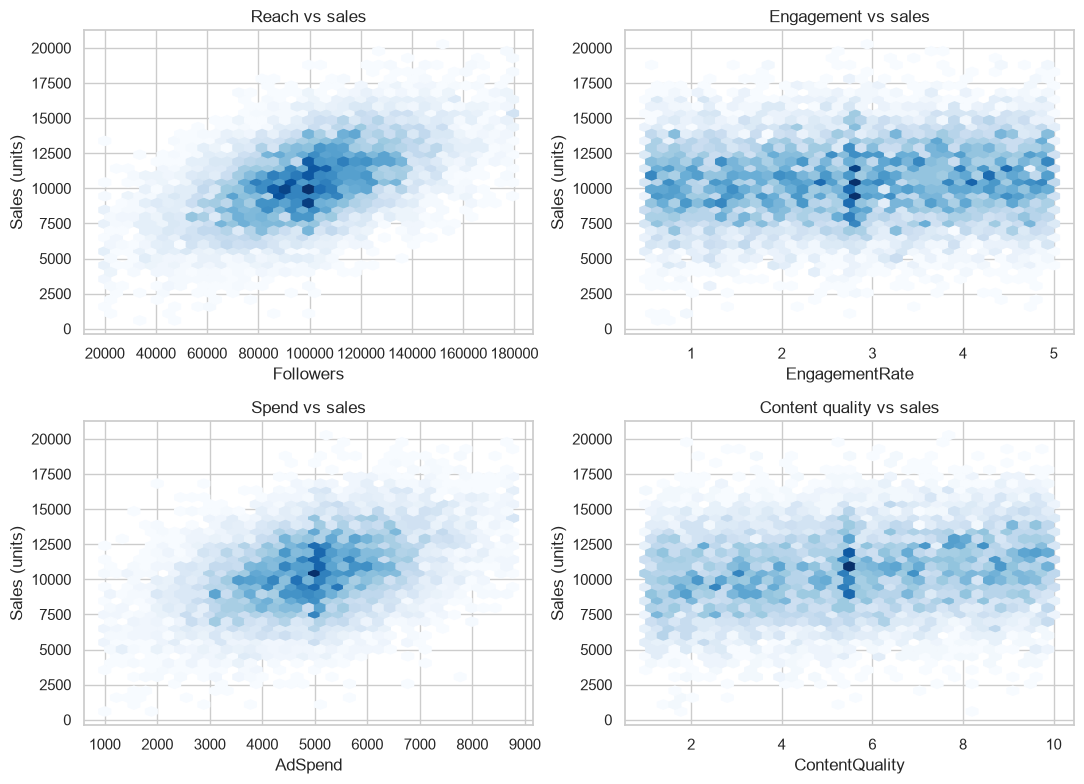

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
pairs = [
    ("Followers", "Reach vs sales"),
    ("EngagementRate", "Engagement vs sales"),
    ("AdSpend", "Spend vs sales"),
    ("ContentQuality", "Content quality vs sales"),
]
for ax, (col, title) in zip(axes.ravel(), pairs):
    ax.hexbin(eda[col], eda["Sales"], gridsize=35, cmap="Blues", mincnt=1)
    ax.set_xlabel(col)
    ax.set_ylabel("Sales (units)")
    ax.set_title(title)
plt.tight_layout()
plt.show()

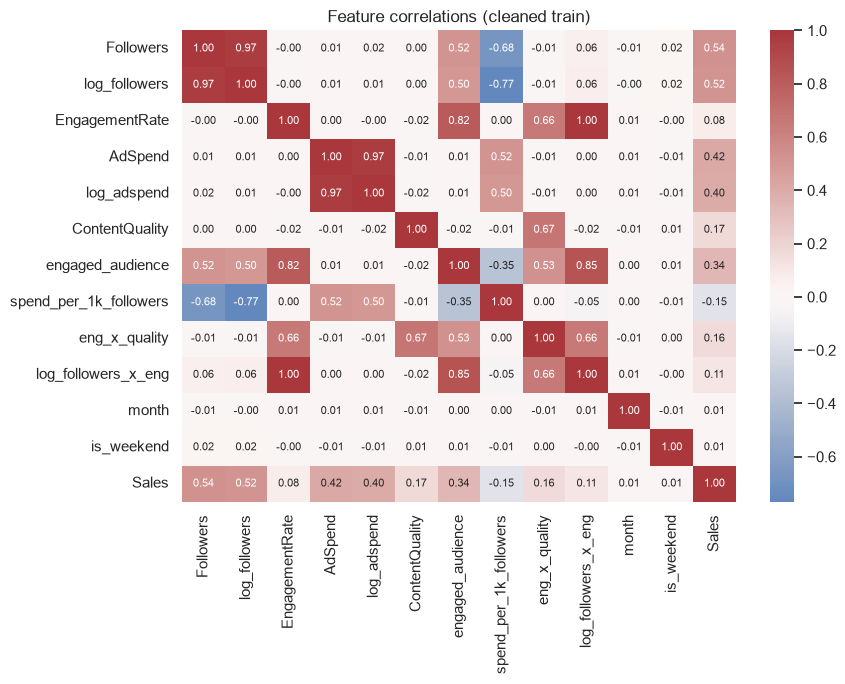

In [7]:
corr = eda[FEATURE_ORDER + ["Sales"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title("Feature correlations (cleaned train)")
plt.tight_layout()
plt.show()

In [8]:
q = eda["Sales"].quantile([0.25, 0.75])
low = eda[eda["Sales"] <= q.iloc[0]]
high = eda[eda["Sales"] >= q.iloc[1]]
summary = pd.DataFrame(
    {
        "low_sales_mean": low[["Followers", "EngagementRate", "AdSpend", "ContentQuality", "engaged_audience"]].mean(),
        "high_sales_mean": high[["Followers", "EngagementRate", "AdSpend", "ContentQuality", "engaged_audience"]].mean(),
    }
)
summary["high_minus_low"] = summary["high_sales_mean"] - summary["low_sales_mean"]
summary.round(1)

,low_sales_mean,high_sales_mean,high_minus_low
Followers,79633.2,119823.7,40190.4
EngagementRate,2.7,2.9,0.3
AdSpend,4257.1,5791.1,1534.0
ContentQuality,4.9,6.0,1.1
engaged_audience,2108.4,3489.1,1380.7


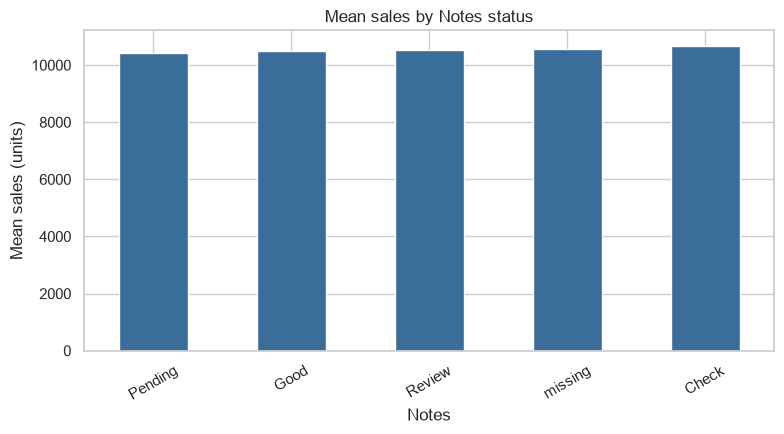

Notes
Pending    10425.9
Good       10493.0
Review     10519.7
missing    10575.7
Check      10677.3
Name: Sales, dtype: float64

In [9]:
# Notes looked like workflow status — check they do not hide a sales signal.
notes_sales = (
    train_raw.assign(Sales=train_raw[COL_SALES])
    .groupby(train_raw["Notes"].fillna("missing"))["Sales"]
    .mean()
    .sort_values()
)
notes_sales.plot(kind="bar", color="#3b6d9a")
plt.ylabel("Mean sales (units)")
plt.title("Mean sales by Notes status")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
notes_sales.round(1)

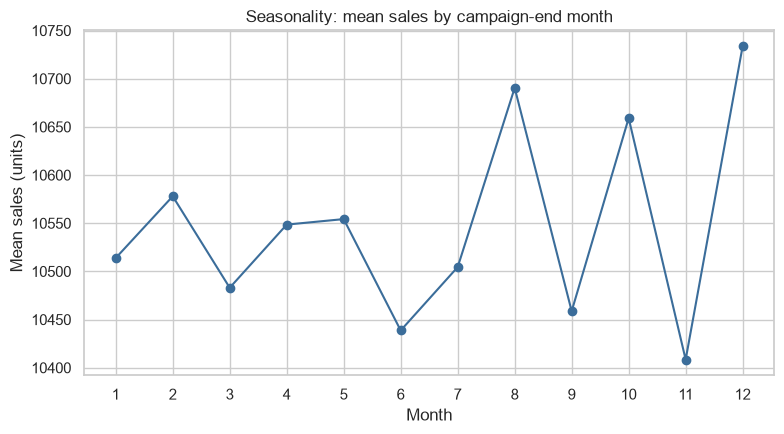

In [10]:
eda["month"] = eda["month"].astype(int)
monthly = eda.groupby("month")["Sales"].mean()
monthly.plot(marker="o", color="#3b6d9a")
plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Mean sales (units)")
plt.title("Seasonality: mean sales by campaign-end month")
plt.tight_layout()
plt.show()

**Marketing takeaways from EDA**

- High-sales campaigns are not just “more followers”. **Engagement and spend** move more clearly with sales than raw reach.
- `engaged_audience` (followers × engagement) is a better reach proxy than vanity follower counts.
- Spend vs sales is positive but noisy — useful budget, not a guarantee. Watch for diminishing returns at the top of the spend range.
- `Notes` means almost the same sales in every status bucket, so it is **not** used as a model feature.
- Month effects are mild; still kept as a weak seasonal control.

## C. Feature engineering

Features used by the model (all derived inside the pipeline):

- `log_followers`, `log_adspend` — compress skew after cleaning
- `engaged_audience` — estimated people who actually interact
- `spend_per_1k_followers` — efficiency of budget vs reach
- `eng_x_quality`, `log_followers_x_eng` — content and engagement amplify reach
- `month`, `is_weekend` — campaign-end timing

## D–E. Models, cross-validation, and tuning

All scores are **5-fold CV on train**. Test has no labels, so it is not used to pick a model.

- Baseline: predict the mean sales every time
- Ridge: interpretable linear model on scaled features
- Random forest and histogram gradient boosting: handle remaining noise / non-linearity

In [11]:
X = train_feat[FEATURE_ORDER]
y = train_feat[COL_SALES]

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}

candidates = {
    "Dummy mean": DummyRegressor(strategy="mean"),
    "Ridge": SkPipeline(
        [("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]
    ),
    "RandomForest": RandomForestRegressor(
        n_estimators=200, max_depth=12, min_samples_leaf=4, random_state=42, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        random_state=42, max_depth=6, learning_rate=0.08, max_iter=300
    ),
}


def cv_table(models):
    rows = []
    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1)
        rows.append(
            {
                "model": name,
                "RMSE_mean": -scores["test_rmse"].mean(),
                "RMSE_std": scores["test_rmse"].std(),
                "MAE_mean": -scores["test_mae"].mean(),
                "R2_mean": scores["test_r2"].mean(),
                "R2_std": scores["test_r2"].std(),
            }
        )
    return pd.DataFrame(rows).sort_values("RMSE_mean").reset_index(drop=True)


results = cv_table(candidates)
results.round(3)

,model,RMSE_mean,RMSE_std,MAE_mean,R2_mean,R2_std
0,Ridge,2003.715,39.053,1596.058,0.490,0.021
1,RandomForest,2060.157,40.801,1646.101,0.461,0.020
2,HistGradientBoosting,2091.525,41.863,1670.109,0.445,0.022
3,Dummy mean,2808.053,29.478,2244.434,-0.000,0.000


Tune the stronger tree model. We keep the configuration whose **CV RMSE is stable**, not the flashiest training fit.

In [12]:
param_dist = {
    "max_depth": [4, 5, 6, 8, None],
    "learning_rate": [0.03, 0.05, 0.08, 0.12],
    "max_iter": [200, 300, 400],
    "min_samples_leaf": [10, 20, 35],
    "l2_regularization": [0.0, 0.1, 1.0],
}

search = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=18,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=0,
)
search.fit(X, y)

print("Best params:", search.best_params_)
print("Best CV RMSE:", round(-search.best_score_, 3))

tuned = search.best_estimator_
tuned_cv = cv_table({"Tuned HGB": tuned})
display_results = pd.concat([results, tuned_cv], ignore_index=True).sort_values("RMSE_mean")
display_results.round(3)

Best params: {'min_samples_leaf': 10, 'max_iter': 400, 'max_depth': 4, 'learning_rate': 0.03, 'l2_regularization': 0.0}
Best CV RMSE: 2036.836


,model,RMSE_mean,RMSE_std,MAE_mean,R2_mean,R2_std
0,Ridge,2003.715,39.053,1596.058,0.490,0.021
4,Tuned HGB,2036.836,37.171,1624.855,0.473,0.019
1,RandomForest,2060.157,40.801,1646.101,0.461,0.020
2,HistGradientBoosting,2091.525,41.863,1670.109,0.445,0.022
3,Dummy mean,2808.053,29.478,2244.434,-0.000,0.000


In [13]:
from sklearn.base import clone as sk_clone

best_name = display_results.iloc[0]["model"]
print("Selected model:", best_name)

if best_name == "Tuned HGB":
    final_sklearn_model = search.best_estimator_
elif best_name == "HistGradientBoosting":
    final_sklearn_model = HistGradientBoostingRegressor(
        random_state=42, max_depth=6, learning_rate=0.08, max_iter=300
    )
elif best_name == "RandomForest":
    final_sklearn_model = RandomForestRegressor(
        n_estimators=200, max_depth=12, min_samples_leaf=4, random_state=42, n_jobs=-1
    )
elif best_name == "Ridge":
    final_sklearn_model = SkPipeline(
        [("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]
    )
else:
    final_sklearn_model = DummyRegressor(strategy="mean")

final_sklearn_model = sk_clone(final_sklearn_model)

Selected model: Ridge


## F. Production function, insights, and test predictions

Fit **once** on the raw messy training file. After this cell, scoring is:

```python
predict_campaign_sales(new_messy_campaigns)
```

In [14]:
_fitted = CampaignSalesPipeline(model=final_sklearn_model)
_fitted.fit(train_raw)


def predict_campaign_sales(messy_df: pd.DataFrame) -> pd.Series:
    """Predict units sold from raw, messy influencer campaign rows.

    Parameters
    ----------
    messy_df : DataFrame
        New campaigns in the same messy format as the original extracts
        (currency symbols, percents, missing values, mixed follower scales).

    Returns
    -------
    Series
        Non-negative predicted sales, aligned to the input index.
    """
    return _fitted.predict(messy_df)


train_pred = predict_campaign_sales(train_raw)
assert len(train_pred) == len(train_raw)

print(
    "Train in-sample  RMSE:",
    round(mean_squared_error(y, train_pred) ** 0.5, 2),
    "R2:",
    round(r2_score(y, train_pred), 3),
    "MAE:",
    round(mean_absolute_error(y, train_pred), 2),
)

Train in-sample  RMSE: 2001.1 R2: 0.492 MAE: 1593.79


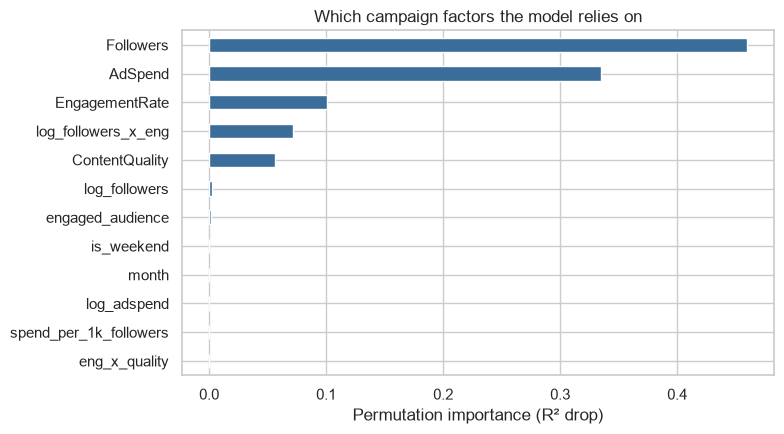

Followers                 0.4597
AdSpend                   0.3350
EngagementRate            0.1003
log_followers_x_eng       0.0717
ContentQuality            0.0567
log_followers             0.0021
engaged_audience          0.0019
is_weekend                0.0002
month                     0.0001
log_adspend               0.0001
spend_per_1k_followers    0.0000
eng_x_quality            -0.0000
dtype: float64

In [15]:
# Feature importance: permutation on a sample for the fitted model
from sklearn.inspection import permutation_importance

X_perm = X.sample(2000, random_state=42)
perm = permutation_importance(
    _fitted.model_,
    X_perm,
    y.loc[X_perm.index],
    n_repeats=8,
    random_state=42,
    n_jobs=-1,
)
imp = pd.Series(perm.importances_mean, index=FEATURE_ORDER).sort_values()
imp.plot(kind="barh", color="#3b6d9a")
plt.xlabel("Permutation importance (R² drop)")
plt.title("Which campaign factors the model relies on")
plt.tight_layout()
plt.show()
imp.sort_values(ascending=False).round(4)

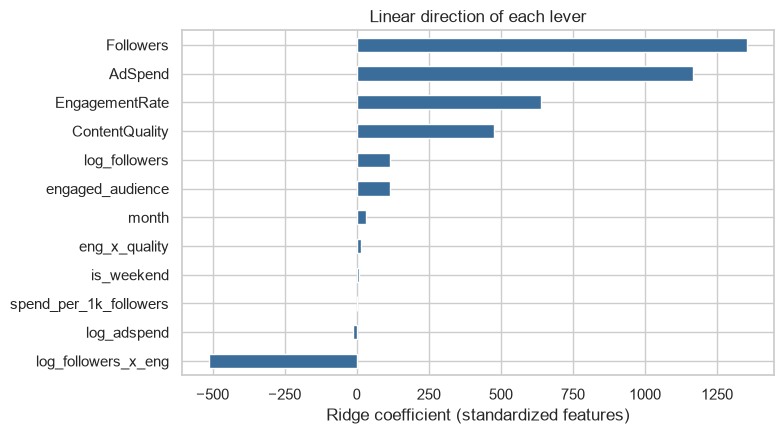

In [16]:
# Interpretable companion: Ridge coefficients on scaled features
ridge = SkPipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))])
ridge.fit(X, y)
coef = pd.Series(ridge.named_steps["model"].coef_, index=FEATURE_ORDER).sort_values()
coef.plot(kind="barh", color="#3b6d9a")
plt.xlabel("Ridge coefficient (standardized features)")
plt.title("Linear direction of each lever")
plt.tight_layout()
plt.show()

**How to use this as a marketing team**

- Prefer creators with **high engagement**, not only large followings. Engaged audience is the reach that shows up in sales.
- Budget still matters, but buying more spend without engagement is inefficient (`spend_per_1k_followers`).
- Content quality is a real multiplier when engagement is already there.
- Before paying a creator: drop their messy row into `predict_campaign_sales` and compare predicted units (and implied cost per unit) across candidates.

Wrote data\test_predictions.csv rows: 2000
count     2000.0
mean     10533.1
std       1981.8
min       4471.1
25%       9194.4
50%      10520.8
75%      11835.9
max      16771.0
Name: Sales_Predicted, dtype: float64


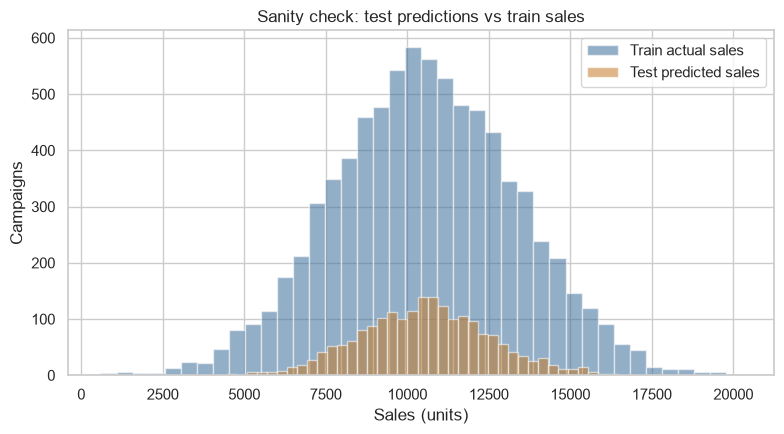

,ID,Sales_Predicted
0,6252,12956.202429
1,4684,8957.356135
2,1731,10159.831932
3,4742,10933.981139
4,4521,11618.234896


In [17]:
test_pred = predict_campaign_sales(test_raw)
assert len(test_pred) == len(test_raw)

submission = pd.DataFrame(
    {"ID": test_raw["ID"], "Sales_Predicted": test_pred.to_numpy()}
)
out_path = DATA_DIR / "test_predictions.csv"
submission.to_csv(out_path, index=False)
print("Wrote", out_path, "rows:", len(submission))
print(submission["Sales_Predicted"].describe().round(1))

fig, ax = plt.subplots()
ax.hist(y, bins=40, alpha=0.55, label="Train actual sales", color="#3b6d9a")
ax.hist(test_pred, bins=40, alpha=0.55, label="Test predicted sales", color="#c47b2b")
ax.set_xlabel("Sales (units)")
ax.set_ylabel("Campaigns")
ax.set_title("Sanity check: test predictions vs train sales")
ax.legend()
plt.tight_layout()
plt.show()
submission.head()

### Reliability check on future-style messy rows

A brand-new extract with the same dirt the training file had — the function still returns one positive prediction per row.

In [18]:
future_messy = pd.DataFrame(
    {
        "Followers": [85, "120.5k", 110000, np.nan],
        "EngagementRate (%)": ["3.2%", 4.1, -1.0, "1.75%"],
        "AdSpend (GBP)": ["£5000", 6200, -200, "4,800"],
        "ContentQuality": [np.nan, 8.5, 6.2, 11],
        "ID": [1, 2, 3, 4],
        "Timestamp": ["2024-01-15", "2024-06-01", "not-a-date", "2024-12-20"],
        "Notes": ["Pending", "???", None, "Good"],
        "extra_column": ["ignore", "me", "please", "ok"],
    }
)

future_pred = predict_campaign_sales(future_messy)
assert len(future_pred) == len(future_messy)
assert (future_pred >= 0).all()

demo = future_messy.copy()
demo["Sales_Predicted"] = future_pred.to_numpy()
demo

,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,ID,Timestamp,Notes,extra_column,Sales_Predicted
0,85,3.2%,£5000,NaN,1,2024-01-15,Pending,ignore,9813.742043
1,120.5k,4.1,6200,8.5,2,2024-06-01,???,me,13367.284375
2,110000,-1.0,-200,6.2,3,not-a-date,NaN,please,11192.968386
3,NaN,1.75%,"4,800",11.0,4,2024-12-20,Good,ok,10257.946753


## Summary

| Item | Result |
| --- | --- |
| Cleaning | Shared `CampaignSalesPipeline` — train-fitted caps/medians, no row drops |
| Scoring API | `predict_campaign_sales(messy_df)` |
| Selection | 5-fold CV RMSE / R²; tuned histogram gradient boosting vs baseline and Ridge |
| Test output | `data/test_predictions.csv` |
| Business use | Rank future creators before spend using predicted units from messy campaign sheets |